# Разведочный анализ данных Альфа Хак

Цель: понять состав и качество трёх наборов данных, связи между компаниями, людьми и платежами, а затем наметить признаки для персонализированной новостной аналитики. Описания полей взяты из приложения 1 к постановке задачи; выводы ниже рассчитываются из данных при запуске.

**Как запустить:** `Run All` из `ml/notebook`. Нужны `pandas`, `numpy`, `matplotlib`, `sqlalchemy`, `psycopg`, `python-dotenv`. Если PostgreSQL доступен на `localhost:15432`, используется он; иначе автоматически читаются CSV из `database/data`. Пароль берётся из `.env`, в ноутбуке не печатается. Источник и ошибка подключения показываются без реквизитов. Для точного снимка данных из БД используйте работающий контейнер; CSV-режим читает файлы проекта.

В данных нет дат платежей и идентификаторов новостей, поэтому временные тренды и проверку качества новостных рекомендаций по этим таблицам построить нельзя.

In [1]:
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 90)
plt.rcParams['figure.figsize'] = (10, 4)

def find_repo_root(start=Path.cwd()):
    for folder in (start, *start.parents):
        if (folder / 'database' / 'data').is_dir():
            return folder
    raise FileNotFoundError('Не найдена database/data. Откройте ноутбук из репозитория.')

ROOT = find_repo_root()
DATA_DIR = ROOT / 'database' / 'data'
print('Корень проекта:', ROOT)

Корень проекта: D:\programming\GitHub\alfa-business-insights


## 1. Загрузка и схема

`synthetic_u` — идентификатор компании. `synthetic_f` — идентификатор физического лица. `payer → beneficiary` задаёт направление платежа. `group_id` описывает группу компаний, а не отдельное физическое лицо. Поля `id` в PostgreSQL добавлены при импорте и не входят в исходные CSV.

Подключение к БД необязательно. Если хотите принудительно читать CSV, установите `USE_DB = False` в следующей ячейке.

In [2]:
from sqlalchemy import create_engine, text, URL
from dotenv import load_dotenv

load_dotenv(ROOT / '.env', override=False)
USE_DB = True
TABLES = {'companies': 'companies', 'people': 'person_company_links', 'payments': 'payments'}
CSV_FILES = {'companies': 'companies.csv', 'people': 'person_company_links.csv', 'payments': 'payment.csv'}

engine = None
source = 'CSV'
if USE_DB and all(os.getenv(k) for k in ('POSTGRES_USER', 'POSTGRES_PASSWORD', 'POSTGRES_DB')):
    try:
        url = URL.create('postgresql+psycopg', username=os.environ['POSTGRES_USER'],
                         password=os.environ['POSTGRES_PASSWORD'], host='localhost', port=15432,
                         database=os.environ['POSTGRES_DB'])
        engine = create_engine(url, connect_args={'connect_timeout': 3})
        with engine.connect() as conn:
            for table in TABLES.values():
                conn.execute(text(f'SELECT 1 FROM {table} LIMIT 1'))
        source = 'PostgreSQL'
    except Exception as exc:
        # Текст драйвера может содержать URL с паролем — выводим только тип ошибки.
        print('БД недоступна:', type(exc).__name__, '→ используем CSV')
        if engine is not None:
            engine.dispose()
        engine = None

def read_dataset(name):
    if source == 'PostgreSQL':
        return pd.read_sql_query(text(f'SELECT * FROM {TABLES[name]}'), engine)
    return pd.read_csv(DATA_DIR / CSV_FILES[name], sep=';', low_memory=False)

companies = read_dataset('companies')
people = read_dataset('people')
payments = read_dataset('payments')
for frame in (companies, people, payments):
    frame.columns = frame.columns.str.lower()
print('Источник:', source)
display(pd.DataFrame({'таблица': ['companies', 'person_company_links', 'payments'],
                      'строк': [len(companies), len(people), len(payments)],
                      'столбцов': [companies.shape[1], people.shape[1], payments.shape[1]]}))

Источник: PostgreSQL


,таблица,строк,столбцов
0,companies,85525,25
1,person_company_links,12514,5
2,payments,1380585,5


In [3]:
# Краткий словарь признаков из постановки; типы и пропуски считаются по фактическим данным.
descriptions = {
    'synthetic_u': 'анонимный идентификатор компании', 'org_type': 'тип организации',
    'okfs_name': 'форма собственности', 'company_age_years_gradation': 'возраст компании, интервал',
    'eco_mark_label': 'экологический маркер', 'mainokved_code': 'основной код ОКВЭД',
    'mainokved_name': 'основной вид деятельности', 'negativemark': 'негативный маркер',
    'amount_workers_fns_gradation': 'численность работников по ФНС, интервал',
    'amount_workers_spark_gradation': 'численность работников по СПАРК, интервал',
    'cl_type': 'тип клиента', 'fts_flag': 'признак внешнеторговой деятельности',
    'fts_country_name': 'страна внешнеторговой деятельности',
    'factoring_mark': 'признак факторинга', 'revenue_company': 'выручка компании',
    'group_id': 'группа компаний', 'city': 'город компании', 'region': 'регион компании',
    'synthetic_f': 'анонимный идентификатор физлица', 'city_name': 'город физлица',
    'rc_name': 'региональный центр физлица', 'beneficiary': 'получатель платежа, компания',
    'payer': 'плательщик, компания', 'pay_amt': 'сумма платежей по паре',
    'pay_cnt': 'число платежей по паре',
}
product_names = {'cl_product_rko_mark': 'РКО', 'cl_product_gar_mark': 'гарантии',
                 'cl_product_loa_mark': 'кредиты', 'cl_product_lea_mark': 'лизинг',
                 'cl_product_dep_mark': 'депозиты', 'cl_product_zpp_mark': 'зарплатный проект'}
descriptions.update({k: 'маркер продукта: ' + v for k, v in product_names.items()})

def profile(frame):
    return pd.DataFrame({
        'описание': [descriptions.get(c, 'служебный ID') for c in frame.columns],
        'тип': frame.dtypes.astype(str),
        'пропуски, %': (frame.isna().mean() * 100).round(1),
        'уникальных': frame.nunique(dropna=True),
        'пример': [str(frame[c].dropna().iloc[0])[:60] if frame[c].notna().any() else '—'
                   for c in frame.columns],
    }, index=frame.columns)

for title, frame in [('Компании', companies), ('Физлица ↔ компании', people), ('Платежи', payments)]:
    print('\n' + title)
    display(profile(frame))


Компании


,описание,тип,"пропуски, %",уникальных,пример
id,служебный ID,int64,0.0,85525,85560
synthetic_u,анонимный идентификатор компании,str,0.0,85514,U_146
org_type,тип организации,str,0.0,1,КОММ_ОРГ
okfs_name,форма собственности,str,0.0,12,ЧАСТНАЯ СОБСТВЕННОСТЬ
company_age_years_gradation,"возраст компании, интервал",str,0.0,4,16-25
eco_mark_label,экологический маркер,str,4.9,4,Оптимизация
mainokved_code,основной код ОКВЭД,str,0.0,546,22.23
mainokved_name,основной вид деятельности,str,0.0,536,"Производство пластмассовых изделий, используемых в строитель"
negativemark,негативный маркер,float64,0.0,2,0.0
amount_workers_fns_gradation,"численность работников по ФНС, интервал",str,0.0,4,Менее 15



Физлица ↔ компании


,описание,тип,"пропуски, %",уникальных,пример
id,служебный ID,int64,0.0,12514,1024
synthetic_f,анонимный идентификатор физлица,str,0.0,11120,F_64255
city_name,город физлица,str,0.1,221,"Мск ""Юг"""
rc_name,региональный центр физлица,str,0.1,10,МОСКОВСКИЙ
synthetic_u,анонимный идентификатор компании,str,0.0,12307,U_146717



Платежи


,описание,тип,"пропуски, %",уникальных,пример
id,служебный ID,int64,0.0,1380585,1
beneficiary,"получатель платежа, компания",str,0.0,115271,U_25835
payer,"плательщик, компания",str,0.0,163363,U_144100
pay_amt,сумма платежей по паре,float64,0.0,79818,16157000.0
pay_cnt,число платежей по паре,int64,0.0,1554,981


## 2. Полнота, уникальность и распределения

Высокая доля пропусков показывает, какие признаки плохо подходят для охвата всех компаний. Большое число уникальных значений помогает отличить идентификаторы от категорий.

In [4]:
for title, frame, key in [('Компании', companies, 'synthetic_u'),
                          ('Связи', people, None), ('Платежи', payments, None)]:
    print(title, '| полных дубликатов:', frame.duplicated().sum(),
          '| дубликатов ключа:' if key else '',
          frame[key].duplicated().sum() if key else '')

categorical = ['cl_type', 'org_type', 'company_age_years_gradation', 'eco_mark_label',
               'mainokved_name', 'region', 'fts_country_name']
for col in categorical:
    if col in companies:
        print('\n', col, '| заполнено:', f'{companies[col].notna().mean():.1%}')
        display(companies[col].fillna('Нет данных').value_counts().head(10).rename('компаний').to_frame())

num_cols = ['revenue_company', 'negativemark', 'fts_flag', 'factoring_mark', *product_names]
display(companies[[c for c in num_cols if c in companies]].apply(pd.to_numeric, errors='coerce')
        .describe(percentiles=[.25, .5, .75, .9, .99]).T.round(2))
display(payments[['pay_amt', 'pay_cnt']].apply(pd.to_numeric, errors='coerce')
        .describe(percentiles=[.25, .5, .75, .9, .99]).T.round(2))

Компании | полных дубликатов: 0 | дубликатов ключа: 11
Связи | полных дубликатов: 0  


Платежи | полных дубликатов: 0  

 cl_type | заполнено: 100.0%


,компаний
cl_type,
CLIENT,41968
PROSPECT,36699
CLOSE_CLIENT,6858



 org_type | заполнено: 100.0%


,компаний
org_type,
КОММ_ОРГ,85525


...

,компаний
region,
Москва,31915
Санкт-Петербург,12780
Новосибирская область,3919
Свердловская область,3750
Республика Татарстан,2770
Московская область,2026
Краснодарский край,1996
Челябинская область,1865
Нижегородская область,1710



 fts_country_name | заполнено: 9.8%


,компаний
fts_country_name,
Нет данных,77179
КИТАЙ,2091
ТУРЦИЯ,291
"КИТАЙ, ТУРЦИЯ",269
УЗБЕКИСТАН,175
"ОАЭ, ИНДИЯ, КИТАЙ",142
"ИНДИЯ, КИТАЙ, ТУРЦИЯ",140
"КИТАЙ, ГОНКОНГ",128
"ИНДИЯ, КИТАЙ, ЛИТВА",116


,count,mean,std,min,25%,50%,75%,90%,99%,max
revenue_company,85525.0,3.797200e+08,1.425250e+09,1000.0,883500.0,33583428.0,240141459.0,909760273.8,5.270933e+09,1.055965e+11
negativemark,85525.0,1.300000e-01,3.400000e-01,0.0,0.0,0.0,0.0,1.0,1.000000e+00,1.000000e+00
fts_flag,85525.0,1.000000e-01,3.000000e-01,0.0,0.0,0.0,0.0,0.0,1.000000e+00,1.000000e+00
factoring_mark,85525.0,0.000000e+00,5.000000e-02,0.0,0.0,0.0,0.0,0.0,0.000000e+00,1.000000e+00
cl_product_rko_mark,85525.0,4.600000e-01,5.000000e-01,0.0,0.0,0.0,1.0,1.0,1.000000e+00,1.000000e+00
cl_product_gar_mark,85525.0,3.000000e-02,1.800000e-01,0.0,0.0,0.0,0.0,0.0,1.000000e+00,1.000000e+00
cl_product_loa_mark,85525.0,6.000000e-02,2.300000e-01,0.0,0.0,0.0,0.0,0.0,1.000000e+00,1.000000e+00
cl_product_lea_mark,85525.0,1.800000e-01,3.800000e-01,0.0,0.0,0.0,0.0,1.0,1.000000e+00,1.000000e+00
cl_product_dep_mark,85525.0,5.000000e-02,2.200000e-01,0.0,0.0,0.0,0.0,0.0,1.000000e+00,1.000000e+00
cl_product_zpp_mark,85525.0,3.100000e-01,4.600000e-01,0.0,0.0,0.0,1.0,1.0,1.000000e+00,1.000000e+00


,count,mean,std,min,25%,50%,75%,90%,99%,max
pay_amt,1380585.0,40556166.83,1.814375e+09,1000.0,44000.0,212000.0,1367000.0,8561000.0,234675080.0,1.118581e+12
pay_cnt,1380585.0,17.76,1.363100e+02,1.0,2.0,5.0,13.0,32.0,219.0,1.246710e+05


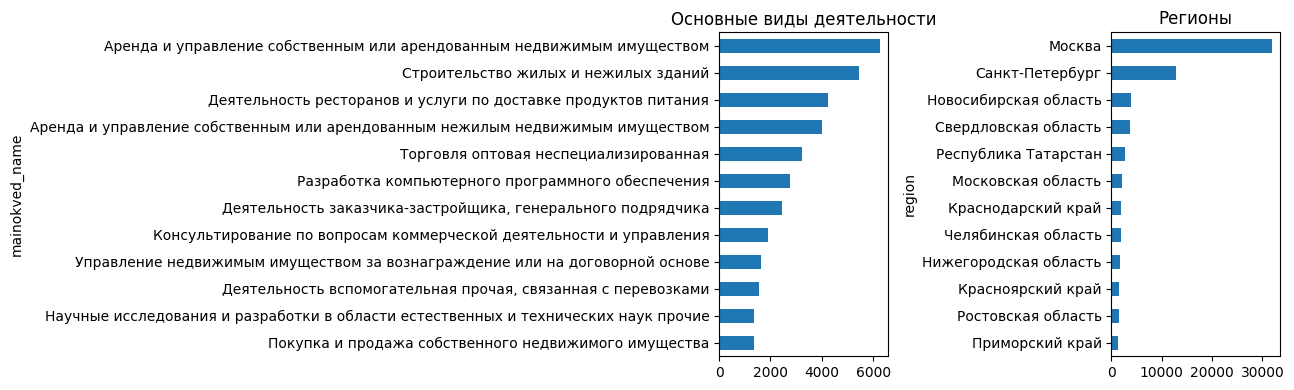

Выручка | нулевых: 0 | отрицательных: 0


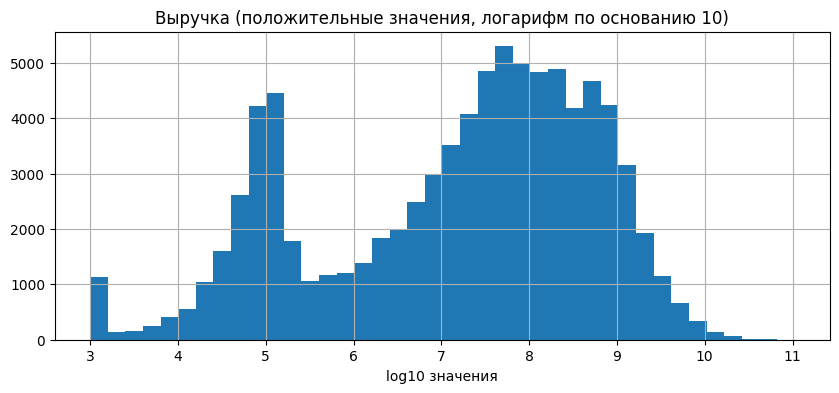

Сумма платежей | нулевых: 0 | отрицательных: 0


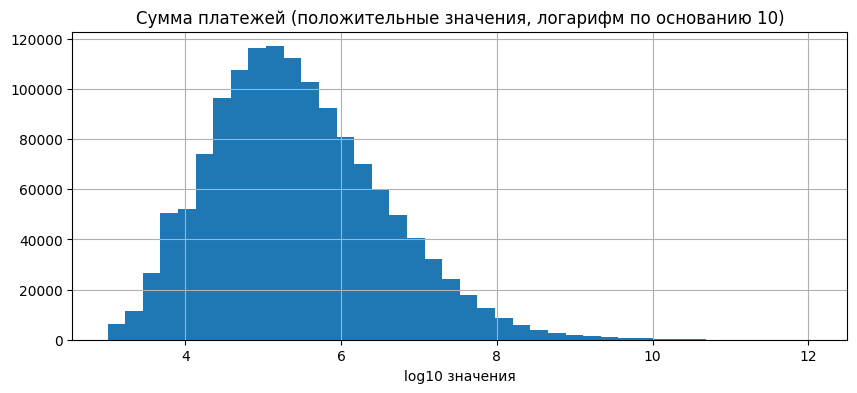

Число платежей | нулевых: 0 | отрицательных: 0


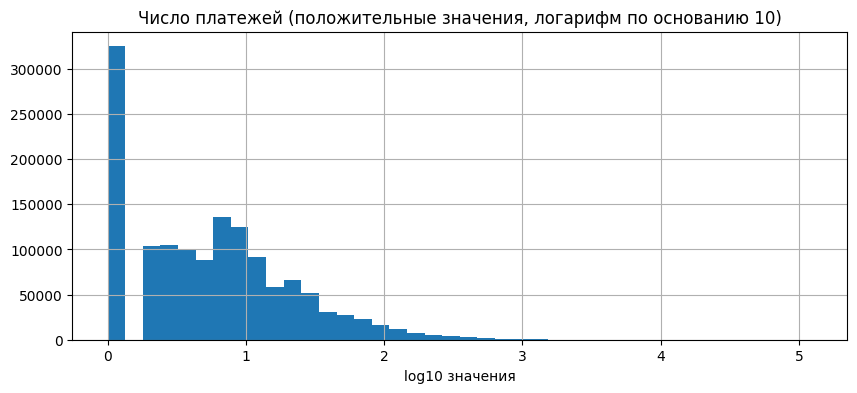

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
companies['mainokved_name'].fillna('Нет данных').value_counts().head(12).sort_values().plot.barh(ax=axes[0], title='Основные виды деятельности')
companies['region'].fillna('Нет данных').value_counts().head(12).sort_values().plot.barh(ax=axes[1], title='Регионы')
plt.tight_layout()
plt.show()

for frame, column, title in [(companies, 'revenue_company', 'Выручка'),
                              (payments, 'pay_amt', 'Сумма платежей'),
                              (payments, 'pay_cnt', 'Число платежей')]:
    values = pd.to_numeric(frame[column], errors='coerce')
    print(title, '| нулевых:', int((values == 0).sum()), '| отрицательных:', int((values < 0).sum()))
    positive = values[values > 0]
    if not positive.empty:
        np.log10(positive).hist(bins=40)
        plt.title(title + ' (положительные значения, логарифм по основанию 10)')
        plt.xlabel('log10 значения')
        plt.show()

## 3. Проверка связей и охвата

Связи проверяются по реальным идентификаторам, без предположения о внешних ключах в SQL. Платежи могут включать контрагентов, отсутствующих в таблице компаний; это влияет на полноту профиля.

In [6]:
company_ids = set(companies['synthetic_u'].dropna())
payer_ids = set(payments['payer'].dropna())
beneficiary_ids = set(payments['beneficiary'].dropna())
person_company_ids = set(people['synthetic_u'].dropna())
coverage = pd.DataFrame([
    ['Связи физлиц → компании', len(person_company_ids), len(person_company_ids & company_ids)],
    ['Плательщики → компании', len(payer_ids), len(payer_ids & company_ids)],
    ['Получатели → компании', len(beneficiary_ids), len(beneficiary_ids & company_ids)],
    ['Все участники платежей → компании', len(payer_ids | beneficiary_ids), len((payer_ids | beneficiary_ids) & company_ids)],
], columns=['связь', 'уникальных ID', 'найдено в companies'])
coverage['охват, %'] = (100 * coverage['найдено в companies'] / coverage['уникальных ID']).round(1)
display(coverage)
print('Компаний без связанного физлица:', len(company_ids - person_company_ids))
print('Компаний без наблюдаемых платежей:', len(company_ids - (payer_ids | beneficiary_ids)))
print('Платежных строк с обеими сторонами в companies:',
      f"{(payments['payer'].isin(company_ids) & payments['beneficiary'].isin(company_ids)).mean():.1%}")

person_degrees = people.groupby('synthetic_f')['synthetic_u'].nunique()
company_people = people.groupby('synthetic_u')['synthetic_f'].nunique()
print('Уникальных физлиц:', len(person_degrees))
print('Физлиц, связанных с >1 компанией:', int((person_degrees > 1).sum()))
display(pd.DataFrame({'компаний на физлицо': person_degrees.describe(percentiles=[.5,.9,.99]),
                      'физлиц на компанию': company_people.describe(percentiles=[.5,.9,.99])}))
print('Повторяющихся пар физлицо–компания:', people.duplicated(['synthetic_f', 'synthetic_u']).sum())
if 'group_id' in companies:
    group_sizes = companies.dropna(subset=['group_id']).groupby('group_id')['synthetic_u'].nunique()
    print('Групп компаний:', len(group_sizes), '| групп с >1 компанией:', int((group_sizes > 1).sum()))
    display(group_sizes.describe(percentiles=[.5,.9,.99]).rename('компаний в группе').to_frame())

,связь,уникальных ID,найдено в companies,"охват, %"
0,Связи физлиц → компании,12307,4519,36.7
1,Плательщики → компании,163363,59668,36.5
2,Получатели → компании,115271,53233,46.2
3,Все участники платежей → компании,178159,63607,35.7


Компаний без связанного физлица: 80995
Компаний без наблюдаемых платежей: 21907


Платежных строк с обеими сторонами в companies: 28.2%
Уникальных физлиц: 11120
Физлиц, связанных с >1 компанией: 969


,компаний на физлицо,физлиц на компанию
count,11120.000000,12307.000000
mean,1.125360,1.016820
std,0.599281,0.153384
min,1.000000,1.000000
50%,1.000000,1.000000
90%,1.000000,1.000000
99%,3.000000,2.000000
max,25.000000,10.000000


Повторяющихся пар физлицо–компания: 0
Групп компаний: 18098 | групп с >1 компанией: 5229


,компаний в группе
count,18098.000000
mean,4.725605
std,21.461634
min,1.000000
50%,1.000000
90%,4.000000
99%,103.000000
max,624.000000


## 4. Платёжная сеть

Строка `payments` агрегирует платежи одной пары компаний: `pay_amt` — общая сумма, `pay_cnt` — количество. Здесь нет дат и отдельных транзакций. Для сравнения отраслей используются только платежи, у которых обе стороны найдены в справочнике компаний.

In [7]:
payments['pay_amt'] = pd.to_numeric(payments['pay_amt'], errors='coerce')
payments['pay_cnt'] = pd.to_numeric(payments['pay_cnt'], errors='coerce')
print('Пар плательщик–получатель:', payments[['payer', 'beneficiary']].drop_duplicates().shape[0])
print('Дублирующихся направленных пар:', payments.duplicated(['payer', 'beneficiary']).sum())
print('Самоплатежей:', int((payments['payer'] == payments['beneficiary']).sum()))
print('Строк с неположительной суммой:', int((payments['pay_amt'] <= 0).sum()))
print('Строк с неположительным числом платежей:', int((payments['pay_cnt'] <= 0).sum()))

outgoing = payments.groupby('payer').agg(out_amount=('pay_amt', 'sum'), out_count=('pay_cnt', 'sum'),
                                          suppliers=('beneficiary', 'nunique'))
incoming = payments.groupby('beneficiary').agg(in_amount=('pay_amt', 'sum'), in_count=('pay_cnt', 'sum'),
                                                customers=('payer', 'nunique'))
company_features = (companies[['synthetic_u', 'mainokved_name', 'region', 'cl_type', 'revenue_company']]
                    .drop_duplicates('synthetic_u').set_index('synthetic_u')
                    .join(outgoing).join(incoming))
print('Компаний с повторяющимся synthetic_u:', companies.loc[companies['synthetic_u'].duplicated(False), 'synthetic_u'].nunique())
print('Для признаков по компании при повторе ID взята первая строка; проверьте расхождения до моделирования.')
for col in ['out_amount','out_count','suppliers','in_amount','in_count','customers']:
    company_features[col] = company_features[col].fillna(0)
company_features['net_inflow'] = company_features['in_amount'] - company_features['out_amount']
company_features['active_in_payments'] = (company_features['out_count'] + company_features['in_count']) > 0
print('Доля компаний с платежами:', f"{company_features['active_in_payments'].mean():.1%}")
display(company_features[['out_amount','in_amount','out_count','in_count','suppliers','customers','net_inflow']]
        .describe(percentiles=[.5,.9,.99]).T.round(2))
display(company_features.nlargest(10, 'in_amount')[['mainokved_name','region','in_amount','customers','out_amount']])

pairs = payments.loc[payments['payer'] != payments['beneficiary'], ['payer','beneficiary']].dropna().drop_duplicates()
reverse = pairs.rename(columns={'payer':'beneficiary','beneficiary':'payer'})
reciprocal = pairs.merge(reverse, on=['payer','beneficiary'], how='inner')
print('Доля направленных пар со встречным платежом:', f'{len(reciprocal)/len(pairs):.1%}' if len(pairs) else 'н/д')

Пар плательщик–получатель: 1380568


Дублирующихся направленных пар: 17
Самоплатежей: 27406
Строк с неположительной суммой: 0
Строк с неположительным числом платежей: 0


Компаний с повторяющимся synthetic_u: 1
Для признаков по компании при повторе ID взята первая строка; проверьте расхождения до моделирования.
Доля компаний с платежами: 74.4%


,count,mean,std,min,50%,90%,99%,max
out_amount,85514.0,6.102092e+08,7.380712e+09,0.000000e+00,788000.0,388851400.0,1.151812e+10,1.123791e+12
in_amount,85514.0,6.139076e+08,7.381282e+09,0.000000e+00,960500.0,397924900.0,1.145910e+10,1.120764e+12
out_count,85514.0,1.898800e+02,1.429420e+03,0.000000e+00,16.0,471.0,2.232870e+03,3.199030e+05
in_count,85514.0,2.051900e+02,1.266490e+03,0.000000e+00,9.0,428.0,2.998960e+03,1.246730e+05
suppliers,85514.0,9.340000e+00,2.331000e+01,0.000000e+00,2.0,25.0,9.000000e+01,1.572000e+03
customers,85514.0,1.136000e+01,7.247000e+01,0.000000e+00,1.0,21.0,1.540000e+02,7.356000e+03
net_inflow,85514.0,3.698477e+06,5.584713e+08,-3.010748e+10,0.0,51245700.0,7.082768e+08,8.183994e+10


,mainokved_name,region,in_amount,customers,out_amount
synthetic_u,,,,,
U_33404,Разработка компьютерного программного обеспечения,Москва,1.120764e+12,24.0,1.123791e+12
U_75345,Торговля оптовая табачными изделиями,Краснодарский край,8.266978e+11,43.0,8.170168e+11
U_179901,"Торговля оптовая производственным электротехническим оборудованием, машинами, аппарату...",Санкт-Петербург,5.172970e+11,21.0,5.175065e+11
U_31747,Торговля оптовая неспециализированная,Москва,3.160877e+11,149.0,3.089549e+11
U_98379,Аренда и управление собственным или арендованным прочим нежилым недвижимым имуществом,Санкт-Петербург,3.154192e+11,5.0,3.160014e+11
U_86785,Производство электромонтажных работ,Свердловская область,2.939458e+11,6.0,3.135778e+11
U_28927,Ремонт машин и оборудования,Санкт-Петербург,2.660294e+11,194.0,2.659111e+11
U_20228,Разработка компьютерного программного обеспечения,Москва,2.657287e+11,86.0,2.758695e+11
U_10578,Разработка компьютерного программного обеспечения,Пермский край,2.381008e+11,10.0,2.380812e+11


Доля направленных пар со встречным платежом: 10.6%


In [8]:
sector = companies[['synthetic_u', 'mainokved_name']].drop_duplicates('synthetic_u')
sector_in = sector.rename(columns={'synthetic_u':'beneficiary','mainokved_name':'отрасль получателя'})
sector_out = sector.rename(columns={'synthetic_u':'payer','mainokved_name':'отрасль плательщика'})
sector_flow = (payments[['payer','beneficiary','pay_amt','pay_cnt']]
               .merge(sector_out, on='payer', how='inner')
               .merge(sector_in, on='beneficiary', how='inner'))
print('Платежных строк с известными отраслями обеих сторон:', len(sector_flow))
display(sector_flow.groupby(['отрасль плательщика','отрасль получателя'], dropna=False)
        .agg(сумма=('pay_amt','sum'), платежей=('pay_cnt','sum'), пар=('payer','size'))
        .nlargest(15, 'сумма').reset_index())

Платежных строк с известными отраслями обеих сторон: 389396


,отрасль плательщика,отрасль получателя,сумма,платежей,пар
0,Разработка компьютерного программного обеспечения,Разработка компьютерного программного обеспечения,3.557112e+12,142286,3251
1,Торговля оптовая неспециализированная,Торговля оптовая неспециализированная,2.701138e+12,215122,3638
2,Строительство жилых и нежилых зданий,Строительство жилых и нежилых зданий,1.933154e+12,135984,2881
3,"Деятельность вспомогательная прочая, связанная с перевозками","Деятельность вспомогательная прочая, связанная с перевозками",1.232642e+12,227073,5636
4,"Торговля оптовая производственным электротехническим оборудованием, машинами, аппарату...","Торговля оптовая производственным электротехническим оборудованием, машинами, аппарату...",1.161256e+12,40509,686
5,Прочие виды строительства жилых и нежилых зданий,Прочие виды строительства жилых и нежилых зданий,9.651289e+11,19897,115
6,"Торговля оптовая прочими машинами, приборами, аппаратурой и оборудованием общепромышле...","Торговля оптовая прочими машинами, приборами, аппаратурой и оборудованием общепромышле...",9.434235e+11,30807,374
7,Торговля оптовая табачными изделиями,Торговля оптовая табачными изделиями,8.568339e+11,4145,38
8,"Деятельность заказчика-застройщика, генерального подрядчика","Деятельность заказчика-застройщика, генерального подрядчика",8.315329e+11,60074,1170
9,"Торговля оптовая компьютерами, периферийными устройствами к компьютерам и программным ...","Торговля оптовая компьютерами, периферийными устройствами к компьютерам и программным ...",7.853600e+11,25571,552


## 5. Сигналы для персонализации новостей

Ниже — обзор сегментов и доступности признаков, а не готовая модель. Маркеры продукта и внешней торговли интерпретируются как флаги только после проверки их значений. Выручка и объём платежей могут иметь разные масштабы и периоды, поэтому их нельзя напрямую делить друг на друга без описания источника.

In [9]:
flags = [*product_names, 'fts_flag', 'factoring_mark', 'negativemark']
flag_summary = []
for col in flags:
    if col in companies:
        values = pd.to_numeric(companies[col], errors='coerce')
        flag_summary.append({'признак': col, 'описание': descriptions[col],
                             'заполнено, %': round(values.notna().mean()*100, 1),
                             '>0, % компаний': round((values > 0).mean()*100, 1),
                             'значения': ', '.join(map(str, sorted(values.dropna().unique())[:12]))})
display(pd.DataFrame(flag_summary))

segment = (company_features.assign(есть_платежи=company_features['active_in_payments'])
           .groupby('mainokved_name', dropna=False)
           .agg(компаний=('есть_платежи','size'), с_платежами=('есть_платежи','sum'),
                входящий_объём=('in_amount','sum'), исходящий_объём=('out_amount','sum')))
segment['охват_платежами_%'] = (100*segment['с_платежами']/segment['компаний']).round(1)
display(segment[segment['компаний'] >= 20].sort_values('компаний', ascending=False).head(20))

,признак,описание,"заполнено, %",">0, % компаний",значения
0,cl_product_rko_mark,маркер продукта: РКО,100.0,46.4,"0.0, 1.0"
1,cl_product_gar_mark,маркер продукта: гарантии,100.0,3.3,"0.0, 1.0"
2,cl_product_loa_mark,маркер продукта: кредиты,100.0,5.8,"0.0, 1.0"
3,cl_product_lea_mark,маркер продукта: лизинг,100.0,17.6,"0.0, 1.0"
4,cl_product_dep_mark,маркер продукта: депозиты,100.0,5.0,"0.0, 1.0"
5,cl_product_zpp_mark,маркер продукта: зарплатный проект,100.0,31.0,"0.0, 1.0"
6,fts_flag,признак внешнеторговой деятельности,100.0,9.8,"0.0, 1.0"
7,factoring_mark,признак факторинга,100.0,0.2,"0.0, 1.0"
8,negativemark,негативный маркер,100.0,13.0,"0.0, 1.0"


,компаний,с_платежами,входящий_объём,исходящий_объём,охват_платежами_%
mainokved_name,,,,,
Аренда и управление собственным или арендованным недвижимым имуществом,6254,4107,6.946527e+11,6.800750e+11,65.7
Строительство жилых и нежилых зданий,5463,3543,2.271504e+12,2.251185e+12,64.9
Деятельность ресторанов и услуги по доставке продуктов питания,4232,3451,7.772249e+11,8.422994e+11,81.5
Аренда и управление собственным или арендованным нежилым недвижимым имуществом,4014,2807,8.408040e+11,8.193799e+11,69.9
Торговля оптовая неспециализированная,3216,2670,3.174137e+12,3.064464e+12,83.0
Разработка компьютерного программного обеспечения,2772,2149,3.720342e+12,3.674711e+12,77.5
"Деятельность заказчика-застройщика, генерального подрядчика",2458,1635,9.878995e+11,1.140171e+12,66.5
Консультирование по вопросам коммерческой деятельности и управления,1916,1151,5.394006e+11,5.196971e+11,60.1
Управление недвижимым имуществом за вознаграждение или на договорной основе,1634,1216,2.377980e+11,2.348097e+11,74.4


### Какие гипотезы проверить дальше

1. **Отрасль + регион:** сопоставлять темы новостей с `mainokved_code`/`mainokved_name` и `region`; сначала оценить полноту этих полей.
2. **Контрагенты:** новости о важных клиентах и поставщиках могут быть полезны; важность можно оценить по `pay_amt`, `pay_cnt` и доле потока, но направление `payer → beneficiary` необходимо сохранять.
3. **Группа и связи физлиц:** расширять охват на связанные компании через `group_id` и `synthetic_f`; это связь, а не доказательство владения или должности.
4. **Продукты и ВЭД:** маркеры кредитов, гарантий, факторинга и стран ВЭД помогают выбирать темы; сначала проверить кодировки и долю пропусков.
5. **Приоритизация:** сочетать релевантность темы, масштаб компании и силу связи; оценивать вручную на небольшой размеченной выборке новостей, так как меток полезности в этих таблицах нет.

Платёжные суммы и выручка могут содержать выбросы; используйте логарифмические шкалы и устойчивые к выбросам статистики. Не показывайте реальные идентификаторы и индивидуальные связи в публичной презентации без проверки правил использования данных.